# Soil sand content (Zarr cube) — raw vs STAC folder vs cloud

Checks that the sand depth cube is the same in the three places it lives:

1. **Raw**: six GeoTIFFs `P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_<depth>.tif` (`float64`)
2. **STAC folder**: `P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\soil_sand_zarr\soil_sand_zarr.zarr` (produced by `notebooks/30_soil_sand_zarr.ipynb`)
3. **Cloud**: the Zarr store found through the public STAC catalog (`gca-stac-7`, collection `soil_sand_zarr`)

The cube is compared with the `float32` cast of every raw depth (values and `NaN` positions). The last sections show what the z dimension gives you: **depth slices** (`sel(depth=...)`), a **depth profile** at a point and a depth range average.

Environment: `environment_exploration.yml` (Miniforge, includes `zarr`, `dask` and `aiohttp` for this notebook).

In [11]:
import time
from pathlib import Path
from posixpath import join as urljoin

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pystac_client
import rasterio
import xarray as xr

## 1) Locations

In [12]:
data_vivian = Path(r"P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian")
DEPTHS = ['0-5cm', '5-15cm', '15-30cm', '30-60cm', '60-100cm', '100-200cm']
VARIABLE = "sand"
raw_paths = {d: data_vivian / f"{VARIABLE}_5km_{d}.tif" for d in DEPTHS}
stac_folder_zarr = data_vivian / "stac" / "soil_sand_zarr" / "soil_sand_zarr.zarr"

gcs_protocol = "https://storage.googleapis.com"
catalog_url = urljoin(gcs_protocol, "gca-data-public", "gca", "gca-stac-7", "catalog.json")
collection_id = "soil_sand_zarr"

for p in (*raw_paths.values(), stac_folder_zarr):
    print(p.exists(), p)

True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_0-5cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_5-15cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_15-30cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_30-60cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_60-100cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\sand_5km_100-200cm.tif
True P:\11209117-041-ipdc-egypt-swi\data\IntDeltaPlatform_QGA\Data_Vivian\stac\soil_sand_zarr\soil_sand_zarr.zarr


## 2) Find the data through the STAC catalog

In [13]:
# public objects are cached for 1 h: a query string forces a fresh copy of catalog.json
catalog = pystac_client.Client.open(f"{catalog_url}?nocache={time.time()}")
# get_collection() can return another collection on a static catalog: match the id explicitly
collection = next((c for c in catalog.get_children() if c.id == collection_id), None)
if collection is None:
    raise LookupError(f"Collection {collection_id} not found in {catalog_url}")

print("Collection:", collection.id, "|", collection.title)
print("cube:dimensions:", list(collection.extra_fields.get("cube:dimensions", {})))
print("cube:variables:", list(collection.extra_fields.get("cube:variables", {})))

# the cube is a collection-level asset (and the data asset of the item)
item = next(collection.get_items())
cloud_href = item.assets["data"].href
assert collection_id in cloud_href, f"Unexpected href: {cloud_href}"
print("data asset:", cloud_href, "|", item.assets["data"].media_type)

c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\client.py:191: NoConformsTo: Server does not advertise any conformance classes.
  warnings.warn(NoConformsTo())


Collection: soil_sand_zarr | SoilGrids250m 2.0 - Sand content
cube:dimensions: ['x', 'y', 'depth']
cube:variables: ['sand', 'depth_bottom', 'depth_top', 'spatial_ref']
data asset: https://storage.googleapis.com/gca-data-public/gca/soil_sand_zarr/soil_sand_zarr.zarr | None


c:\Users\fuentesm\AppData\Local\miniforge3\envs\gca-exploration\Lib\site-packages\pystac_client\collection_client.py:149: FallbackToPystac: Falling back to pystac. This might be slow.
  root._warn_about_fallback("ITEM_SEARCH")


## 3) Open the stores

The cloud store is read lazily over HTTPS: only the chunks that are used are downloaded.

In [14]:
raw = {}
for d, p in raw_paths.items():
    with rasterio.open(p) as src:
        raw[d] = src.read(1).astype("float32")  # the cube is float32

# the cloud store needs its consolidated metadata (.zmetadata) to list the variables over HTTPS
cubes = {
    "stac folder (P:)": xr.open_zarr(stac_folder_zarr, consolidated=False),
    "cloud (catalog)": xr.open_zarr(cloud_href),
}
for label, ds in cubes.items():
    print(f"--- {label}")
    print(ds)

--- stac folder (P:)
<xarray.Dataset> Size: 83MB
Dimensions:       (depth: 6, y: 2076, x: 1671)
Coordinates:
  * depth         (depth) float64 48B 2.5 10.0 22.5 45.0 80.0 150.0
    depth_bottom  (depth) int64 48B dask.array<chunksize=(6,), meta=np.ndarray>
    depth_top     (depth) int64 48B dask.array<chunksize=(6,), meta=np.ndarray>
  * y             (y) float64 17kB 46.6 46.56 46.51 ... -46.51 -46.56 -46.6
  * x             (x) float64 13kB -20.01 -19.97 -19.92 ... 54.91 54.95 55.0
    spatial_ref   int64 8B ...
Data variables:
    sand          (depth, y, x) float32 83MB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
Attributes: (12/28)
    TITLE:               SoilGrids250m 2.0 - Sand content
    TITLE_ABBREVIATION:  SoilSandZarr
    DESCRIPTION:         Sand content (50/63-2000 micro meter) mass fraction ...
    SHORT_DESCRIPTION:   Sand content for different depth intervals, globally.
    INSTITUTION:         SOILGrids
    PROVIDERS:           {"name": "ISRIC", "url": "htt

## 4) Compare

In [15]:
results = []
for label, ds in cubes.items():
    da = ds[VARIABLE]
    for i, d in enumerate(DEPTHS):
        new = da.isel(depth=i).values
        old = raw[d]
        same_shape = old.shape == new.shape
        same_mask = same_shape and np.array_equal(np.isnan(old), np.isnan(new))
        n_diff = int((old[~np.isnan(old)] != new[~np.isnan(old)]).sum()) if same_mask else None
        results.append({
            "cube": label, "depth": d, "depth coord (cm)": float(da.depth[i]),
            "same shape": same_shape, "same valid mask": same_mask,
            "different valid pixels": n_diff, "identical": bool(same_mask and n_diff == 0),
        })
display(pd.DataFrame(results))

attrs = {label: (ds[VARIABLE].dtype, ds[VARIABLE].encoding.get("chunks"), ds.attrs.get("COLLECTION_ID")) for label, ds in cubes.items()}
print(attrs)

if all(r["identical"] for r in results):
    print("OK: raw, stac folder and cloud contain exactly the same data.")
else:
    print("MISMATCH: see the table above.")

,cube,depth,depth coord (cm),same shape,same valid mask,different valid pixels,identical
0,stac folder (P:),0-5cm,2.5,True,True,0,True
1,stac folder (P:),5-15cm,10.0,True,True,0,True
2,stac folder (P:),15-30cm,22.5,True,True,0,True
3,stac folder (P:),30-60cm,45.0,True,True,0,True
4,stac folder (P:),60-100cm,80.0,True,True,0,True
5,stac folder (P:),100-200cm,150.0,True,True,0,True
6,cloud (catalog),0-5cm,2.5,True,True,0,True
7,cloud (catalog),5-15cm,10.0,True,True,0,True
8,cloud (catalog),15-30cm,22.5,True,True,0,True
9,cloud (catalog),30-60cm,45.0,True,True,0,True


{'stac folder (P:)': (dtype('float32'), (1, 512, 512), 'soil_sand_zarr'), 'cloud (catalog)': (dtype('float32'), (1, 512, 512), 'soil_sand_zarr')}
OK: raw, stac folder and cloud contain exactly the same data.


## 5) Depth slices (z)

One `sel` per depth gives a 2D map; the same slicing works on the local and the cloud cube.

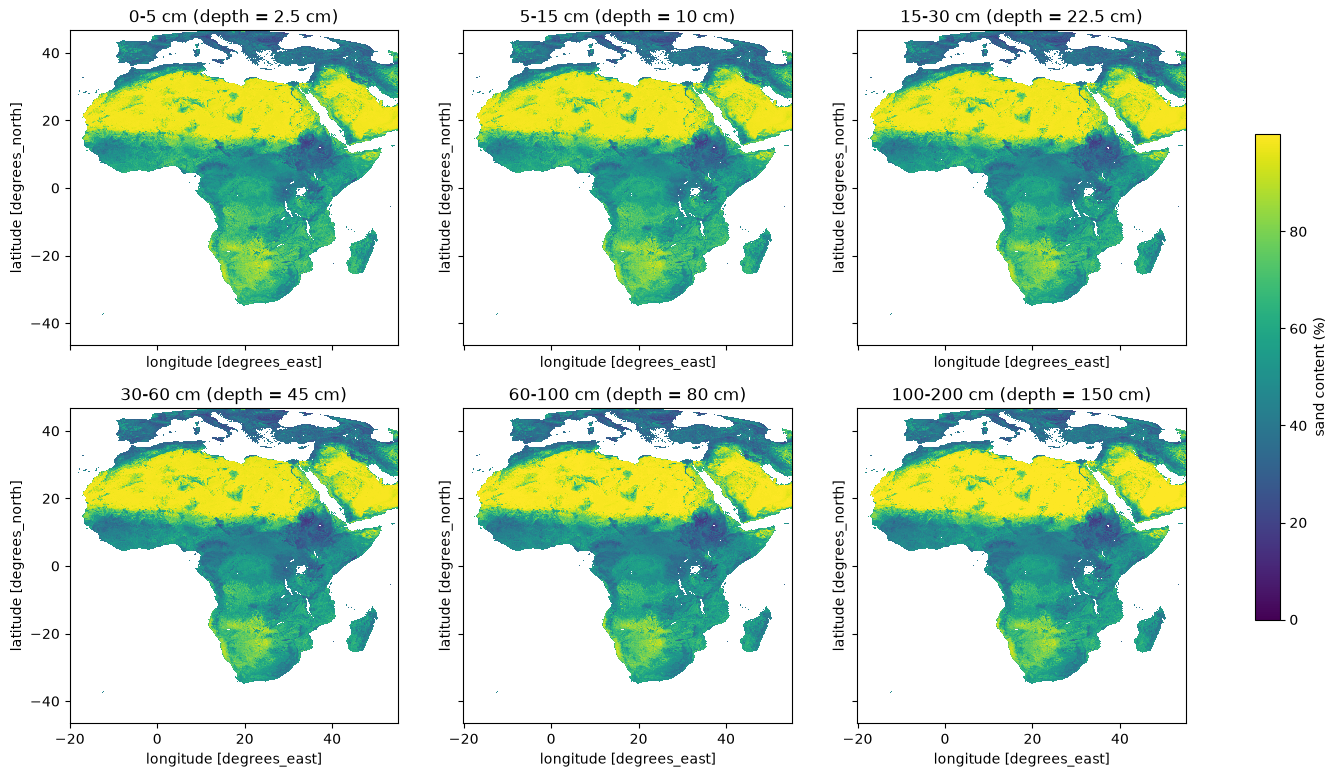

In [16]:
cube = cubes["cloud (catalog)"][VARIABLE].load()
vmax = float(cube.quantile(0.99))

fig, axes = plt.subplots(2, 3, figsize=(18, 9), sharex=True, sharey=True)
for ax, depth in zip(axes.ravel(), cube.depth.values):
    im = cube.sel(depth=depth).plot(ax=ax, cmap="viridis", vmin=0, vmax=vmax, add_colorbar=False)
    top, bottom = int(cube.depth_top.sel(depth=depth)), int(cube.depth_bottom.sel(depth=depth))
    ax.set_title(f"{top}-{bottom} cm (depth = {depth:g} cm)")
fig.colorbar(im, ax=axes, label="sand content (%)", shrink=0.7)
plt.show()

## 6) Depth profile and depth range

A profile along z at one point, and the average of the 0-30 cm layers (topsoil). With the COG variant this needs six separate reads, here it is one array.

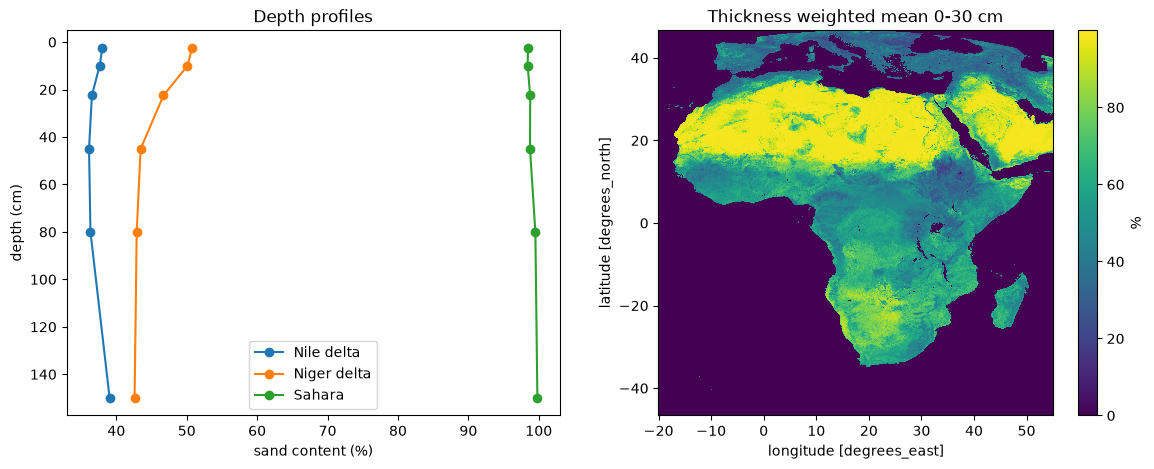

In [17]:
points = {"Nile delta": (31.0, 30.5), "Niger delta": (6.0, 5.0), "Sahara": (15.0, 25.0)}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, (lon, lat) in points.items():
    profile = cube.sel(x=lon, y=lat, method="nearest")
    axes[0].plot(profile.values, profile.depth.values, marker="o", label=name)
axes[0].invert_yaxis()
axes[0].set_xlabel("sand content (%)")
axes[0].set_ylabel("depth (cm)")
axes[0].legend()
axes[0].set_title("Depth profiles")

# interval average of the layers whose top lies within 0-30 cm (weighted by the layer thickness)
top_layers = cube.where(cube.depth_bottom <= 30, drop=True)
thickness = (top_layers.depth_bottom - top_layers.depth_top)
topsoil = (top_layers * thickness).sum("depth") / thickness.sum()
topsoil.plot(ax=axes[1], cmap="viridis", vmin=0, vmax=vmax, cbar_kwargs={"label": "%"})
axes[1].set_title("Thickness weighted mean 0-30 cm")
plt.show()